# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: Triangulados

# Integrantes
* Posse Lucila
* Ventroni Milena
* Pili
* Fran


### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 8.


### Solución
#### 1.a. Rango y cantidad mínima de puntos

Para que el sistema homogéneo $Qm=0$ tenga una solución no nula única salvo un factor de escala, es necesario que el núcleo de $Q$ tenga dimensión 1. Por el teorema de rango-nulidad, dado que $Q$ tiene 12 columnas:

$$
\operatorname{rg}(Q)+\dim(\ker Q)=12
$$

Por lo tanto su rango debe ser exactamente 11.

Como cada correspondencia entre un punto 3D y su proyección 2D aporta dos filas a $Q$, se necesitan como mínimo 6 puntos:

$$
2n\geq11\implies n\geq6
$$

Sin embargo, no cualquier conjunto de 6 puntos es suficiente: deben encontrarse posicionados de una manera tal que la matriz $Q$ resultante tenga rango 11. En particular, <u>los puntos no pueden ser todos coplanares</u>.

**Justificación de la no coplanaridad**

Si todos los puntos 3D son coplanares, existe un vector no nulo $a\in\mathbb{R}^4$ tal que:

$$
a^TP_i=0 \qquad \forall i
$$

donde $P_i=(U_i,V_i,W_i,1)^T$.

Recordando que cada punto aporta dos filas a $Q$:

$$
Q_i=
\begin{pmatrix}
P_i^T & 0^T & -u_iP_i^T\\
0^T & P_i^T & -v_iP_i^T
\end{pmatrix}
$$

Como $a^TP_i=0$, los siguientes vectores pertenecen al núcleo de $Q$:

$$
m_1=
\begin{pmatrix}a\\0\\0\end{pmatrix},
\qquad
m_2=
\begin{pmatrix}0\\a\\0\end{pmatrix},
\qquad
m_3=
\begin{pmatrix}0\\0\\a\end{pmatrix}
$$

Estos tres vectores son linealmente independientes, ya que $a\neq0$ y ocupa bloques distintos en cada uno.

Además, el vector $m$ correspondiente a la matriz de proyección de la cámara también pertenece al núcleo de $Q$. Como dicha matriz representa una cámara válida, no puede tener todas sus filas proporcionales a $a^T$, por lo que $m$ es linealmente independiente de $m_1,m_2,m_3$.

Entonces:

$$
\dim(\ker Q)\geq4
$$

Por rango-nulidad:

$$
\operatorname{rg}(Q)=12-\dim(\ker Q)\leq8
$$

Por lo tanto, si todos los puntos son coplanares, $Q$ no puede alcanzar rango 11. Esto demuestra que los puntos no pueden ser todos coplanares para determinar una única matriz de proyección salvo escala.

#### 1.b. Minimización

Buscamos el vector $m$ que resuelve:

$$
\min_{\|m\|_2=1}m^TQ^TQm
=
\min_{\|m\|_2=1}\|Qm\|_2^2
$$

##### Descomposición en valores singulares (SVD)

Consideramos la descomposición en valores singulares de $Q$, continuando el item 1a. $Q\in\mathbb{R}^{12\times12}$:

$$
Q=U\Sigma V^T
$$

Entonces:

$$
\begin{aligned}
Q^TQ
&=(V\Sigma^TU^T)(U\Sigma V^T)\\
&=V\Sigma^2V^T
\end{aligned}
$$

donde utilizamos que $U^TU=I$ y que $\Sigma$ es diagonal, por lo que $\Sigma^T=\Sigma$.

Como $\Sigma^2$ es una matriz diagonal cuyos elementos son los cuadrados de los valores singulares, reemplazamos en la expresión a minimizar:

$$
\min_{\|m\|_2=1}m^TV\Sigma^2V^Tm
$$

Realizamos el cambio de variable:

$$
y^T=m^TV
\quad\Longrightarrow\quad
y=V^Tm
$$

Como $V$ es ortogonal:

$$
\|y\|_2^2=y^Ty=m^TVV^Tm=m^Tm=1
$$

De esta manera, el problema queda:

$$
\min_{\|y\|_2=1}y^T\Sigma^2y
$$

Considerando los valores singulares ordenados de mayor a menor:

$$
\sigma_1\geq\sigma_2\geq\cdots\geq\sigma_{12}\geq0
$$

Tenemos:

$$
\begin{aligned}
y^T\Sigma^2y
&=\sum_{i=1}^{12}\sigma_i^2y_i^2\\
&\geq\sigma_{12}^2\sum_{i=1}^{12}y_i^2\\
&=\sigma_{12}^2\|y\|_2^2\\
&=\sigma_{12}^2
\end{aligned}
$$

Por lo tanto:

$$
m^TQ^TQm\geq\sigma_{12}^2
$$

Para alcanzar esta cota inferior, tomamos:

$$
y=e_{12}=(0,\ldots,0,1)^T
$$

Este vector cumple $\|y\|_2=1$ y:

$$
y^T\Sigma^2y=\sigma_{12}^2
$$

Como $y=V^Tm$, recuperamos:

$$
m=Vy=Ve_{12}=v_{12}
$$

Es decir, $m$ es la última columna de $V$, asociada al menor valor singular de $Q$.

Por lo tanto:

$$
\boxed{
\min_{\|m\|_2=1}m^TQ^TQm=\sigma_{12}^2
}
$$

Y una solución es:

$$
\boxed{m=v_{12}}
$$

ya que los autovalores de $Q^TQ$ son los cuadrados de los valores singulares de $Q$:

$$
\boxed{
\lambda_{\min}(Q^TQ)=\sigma_{12}^2
}
$$

Por lo tanto, podemos obtener el vector $m$ como un autovector unitario asociado al menor autovalor de $Q^TQ$, o equivalentemente como la última columna de $V$ en la descomposición SVD de $Q$.


### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



### Solución
#### Ejercicio 2.a — Calibración de puntos 3d

Para recuperar los parámetros intrínsecos y extrínsecos de la cámara, partimos de las correspondencias entre los puntos del mundo real y sus proyecciones en la imagen.

En primer lugar, construimos la matriz $Q$ mediante la función `obtenerQ3d`, siguiendo la ecuación (6) del enunciado.

Cada correspondencia aporta dos filas:

$$
Q_i=
\begin{pmatrix}
P_i^T & 0^T & -u_iP_i^T\\
0^T & P_i^T & -v_iP_i^T
\end{pmatrix},
$$

donde $P_i=(U_i,V_i,W_i,1)^T$.

Para la primera captura contamos con 12 correspondencias, por lo que:

$$
Q\in\mathbb{R}^{24\times12}.
$$

A continuación, recuperamos la matriz de proyección $M$ mediante la función `resolverDLT3D`. Como vimos en el ejercicio 1.b, el vector unitario que minimiza $\|Qm\|_2^2$ es un autovector asociado al menor autovalor de $Q^TQ$.

Para obtenerlo, utilizamos la función `diagRH` del módulo `alc` y reorganizamos el vector resultante en una matriz de $3\times4$.

Finalmente, buscamos descomponer la matriz de proyección como:

$$
M\sim K[R\mid t],
$$

donde $K$ contiene los parámetros intrínsecos, $R$ es la matriz de rotación y $t$ es el vector de traslación.

Como $M$ está determinada salvo un factor de escala, la normalizamos antes de aplicar `devolverMatricesCalibracion3d`. Esta función utiliza una factorización QR para recuperar los parámetros de calibración.

Para verificar los resultados, comprobamos que:

$$
R^TR\approx I,
\qquad
\det(R)\approx1.
$$



In [5]:
# Ejercicio 2.a - Calibración con puntos 3D

import numpy as np
import os
import alc
import pandas as pd #se usa más adelante

# 1. Cargamos los datos
ruta_puntos_3d = os.path.join("calib", "3d", "p_W_corners.txt")
ruta_puntos_2d = os.path.join("calib", "3d", "detected_corners.txt")

objPts_3d = np.loadtxt(ruta_puntos_3d, delimiter=",")
datos_3d = np.loadtxt(ruta_puntos_2d)

# Utilizamos la primera captura
imgPts_3d = datos_3d[0].reshape(12, 2)

# 2. Construimos la matriz Q
Q_3d = alc.obtenerQ3d(imgPts_3d, objPts_3d)

np.set_printoptions(threshold=50, precision=2, suppress=True)

print("Dimensiones de Q:", Q_3d.shape)
print("\nMatriz Q (resumida):")
print(Q_3d)

# 3. Recuperamos la matriz de proyección M
M_3d = alc.resolverDLT3D(Q_3d)

print("\nDimensiones de M:", M_3d.shape)
print("\nMatriz de proyección M:")
print(M_3d)

# Verificamos la normalización y el residuo
m_3d = M_3d.reshape(12)
residuo_3d = alc.matvec(Q_3d, m_3d)

print("\nNorma de m:", alc.norma(m_3d, 2))
print("Norma de Qm:", alc.norma(residuo_3d, 2))

# 4. Normalizamos M para recuperar K, R y t
escala_3d = alc.norma(M_3d[2, :3], 2)
M_normalizada = M_3d / escala_3d

R_3d, t_3d, K_3d = alc.devolverMatricesCalibracion3d(M_normalizada)

print("\nMatriz K:")
print(K_3d)

print("\nMatriz R:")
print(R_3d)

print("\nVector t:")
print(t_3d)

# 5. Verificamos que R sea una matriz de rotación
RtR_3d = alc.multiplicacion_matrices(
    alc.transpuesta(R_3d), R_3d
)

print("\nR^T R:")
print(RtR_3d)

det_R = (
    R_3d[0, 0] * (R_3d[1, 1]*R_3d[2, 2] - R_3d[1, 2]*R_3d[2, 1])
    - R_3d[0, 1] * (R_3d[1, 0]*R_3d[2, 2] - R_3d[1, 2]*R_3d[2, 0])
    + R_3d[0, 2] * (R_3d[1, 0]*R_3d[2, 1] - R_3d[1, 1]*R_3d[2, 0])
)

print("\nDeterminante de R:", det_R)


Dimensiones de Q: (24, 12)

Matriz Q (resumida):
[[     0.        8.        0.   ...  -1492.       -0.     -186.5 ]
 [     0.        0.        0.   ...  -1500.       -0.     -187.5 ]
 [    10.4       8.        0.   ...  -2116.       -0.     -264.5 ]
 ...
 [     0.        0.        0.   ...  -7012.5    3071.47   -280.5 ]
 [    19.4      25.      -24.45 ... -12412.5   12139.42   -496.5 ]
 [     0.        0.        0.   ...  -7512.5    7347.22   -300.5 ]]

Dimensiones de M: (3, 4)

Matriz de proyección M:
[[-0.06 -0.02  0.01 -0.84]
 [-0.   -0.06 -0.01 -0.54]
 [-0.   -0.   -0.   -0.01]]

Norma de m: 1.0
Norma de Qm: 0.008222745610321923

Matriz K:
[[425.86  -0.02 354.42]
 [  0.   424.57 256.85]
 [  0.     0.     1.  ]]

Matriz R:
[[ 0.62  0.13 -0.78]
 [-0.36  0.93 -0.13]
 [ 0.7   0.35  0.62]]

Vector t:
[-18.17 -14.5   40.59]

R^T R:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

Determinante de R: 1.0


#### Ejercicio 2.b — Restricción sobre los factores de escala

En este inciso, buscamos recuperar un nuevo conjunto de parámetros imponiendo que los factores de escala de la matriz intrínseca sean iguales:

$$
\alpha_u=\alpha_v.
$$

Para ello, utilizamos el parámetro opcional `restric="alfa"` de la función `devolverMatricesCalibracion3d`.

La implementación toma el promedio de los factores de escala obtenidos inicialmente e impone ese valor para ambos. A continuación, recalcula los parámetros extrínsecos y ortonormaliza la matriz de rotación.

Como estamos imponiendo una restricción adicional, la descomposición resultante puede aproximar la matriz de proyección original.


In [2]:
# Ejercicio 2.b - Restricción alfa_u = alfa_v

R_alfa, t_alfa, K_alfa = alc.devolverMatricesCalibracion3d(
    M_normalizada, restric="alfa"
)

print("Matriz K:")
print(K_alfa)

print("\nMatriz R:")
print(R_alfa)

print("\nVector t:")
print(t_alfa)

# Verificamos la restricción
print("\nAlfa_u:", K_alfa[0, 0])
print("Alfa_v:", K_alfa[1, 1])
print("Diferencia:", K_alfa[0, 0] - K_alfa[1, 1])


Matriz K:
[[425.21  -0.02 354.42]
 [  0.   425.21 256.85]
 [  0.     0.     1.  ]]

Matriz R:
[[ 0.62  0.13 -0.78]
 [-0.36  0.93 -0.13]
 [ 0.7   0.35  0.62]]

Vector t:
[-18.2  -14.48  40.59]

Alfa_u: 425.2125845602298
Alfa_v: 425.2125845602298
Diferencia: 0.0


#### Ejercicio 2.c — Restricción sobre el parámetro de oblicuidad

En este inciso, buscamos recuperar un nuevo conjunto de parámetros imponiendo que el parámetro de oblicuidad (*skew*) sea nulo:

$$
K_{12}=0.
$$

Para ello, utilizamos el parámetro opcional `restric="skew"` de la función `devolverMatricesCalibracion3d`.

Esta restricción corresponde a considerar que los ejes de la grilla de píxeles son perpendiculares.

La implementación modifica la matriz de parámetros intrínsecos y recalcula los parámetros extrínsecos correspondientes, ortonormalizando nuevamente la matriz de rotación.


In [3]:
# Ejercicio 2.c - Restricción K_12 = 0

R_skew, t_skew, K_skew = alc.devolverMatricesCalibracion3d(
    M_normalizada, restric="skew"
)

print("Matriz K:")
print(K_skew)

print("\nMatriz R:")
print(R_skew)

print("\nVector t:")
print(t_skew)

# Verificamos la restricción
print("\nParámetro skew:", K_skew[0, 1])


Matriz K:
[[425.86   0.   354.42]
 [  0.   424.57 256.85]
 [  0.     0.     1.  ]]

Matriz R:
[[ 0.62  0.13 -0.78]
 [-0.36  0.93 -0.13]
 [ 0.7   0.35  0.62]]

Vector t:
[-18.17 -14.5   40.59]

Parámetro skew: 0.0


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.


### Solución
#### Ejercicio 3.a — Construcción de la matriz Q

Para obtener la matriz de parámetros intrínsecos $K$, utilizamos el método de calibración con puntos coplanares.

El tablero contiene 77 esquinas internas, distribuidas en 11 columnas y 7 filas, separadas por 30 mm. Como todos los puntos pertenecen a un mismo plano, consideramos sus coordenadas $(U,V)$, tomando $W=0$.

Para cada imagen, construimos una matriz $Q_j$ a partir de las correspondencias entre los puntos del tablero y sus proyecciones. Cada correspondencia aporta dos ecuaciones, por lo que:

$$
Q_j\in\mathbb{R}^{154\times9}.
$$

Luego, mediante la función `resolverDLT2D`, obtenemos la homografía $H_j$ asociada a cada vista, que relaciona las coordenadas del tablero con las coordenadas de la imagen:

$$
\lambda
\begin{pmatrix}
u\\v\\1
\end{pmatrix}
=
H_j
\begin{pmatrix}
U\\V\\1
\end{pmatrix}.
$$

A partir de las homografías, construimos la matriz $A$ mediante la función `armarA`. Finalmente, utilizamos `calcularMatrizK2D` para recuperar la matriz de parámetros intrínsecos:

$$
K=
\begin{pmatrix}
\alpha_u & s & u_0\\
0 & \alpha_v & v_0\\
0 & 0 & 1
\end{pmatrix}.
$$

Para este cálculo utilizamos las diez imágenes disponibles en la carpeta de calibración.


In [11]:
# Cargamos las coordenadas de las esquinas
ruta_coplanar = os.path.join("calib", "coplanar", "marcadas")
ruta_esquinas = os.path.join(ruta_coplanar, "esquinas.csv")

esquinas = pd.read_csv(ruta_esquinas)

# Path de imágenes + sanity check de que sean 20
imagenes = [file for file in os.listdir(ruta_coplanar) if file.endswith(".png")]
assert(len(imagenes) == 20)


# Construimos Q y calculamos H para cada imagen
matrices_Q = {}
matrices_H = {}
Hlist = []


for imagen in imagenes:
    # Seleccionamos las correspondencias de la imagen
    datos_img = esquinas[esquinas["imagen"] == imagen]

    objPts = np.asarray(datos_img[["U", "V"]])
    imgPts = np.asarray(datos_img[["u", "v"]])

    # Construimos Q
    Q = alc.obtenerQ2d(imgPts, objPts)
    matrices_Q[imagen] = Q

    # Recuperamos la homografía
    H = alc.resolverDLT2D(Q)
    matrices_H[imagen] = H
    Hlist.append(H)

    print(f"{imagen}: Q {Q.shape}, H {H.shape}")

# Construimos la matriz A
A = alc.armarA(Hlist)

print("\nCantidad de homografías:", len(Hlist))
print("Dimensiones de A:", A.shape)

# Calculamos la matriz K
K = alc.calcularMatrizK2D(A)

print("\nMatriz de parámetros intrínsecos K:")
print(K)


Im_R_17.png: Q (154, 9), H (3, 3)
Im_R_6.png: Q (154, 9), H (3, 3)
Im_R_7.png: Q (154, 9), H (3, 3)
Im_R_16.png: Q (154, 9), H (3, 3)
Im_R_14.png: Q (154, 9), H (3, 3)
Im_R_5.png: Q (154, 9), H (3, 3)
Im_R_4.png: Q (154, 9), H (3, 3)
Im_R_15.png: Q (154, 9), H (3, 3)
Im_R_11.png: Q (154, 9), H (3, 3)
Im_R_1.png: Q (154, 9), H (3, 3)
Im_R_10.png: Q (154, 9), H (3, 3)
Im_R_12.png: Q (154, 9), H (3, 3)
Im_R_3.png: Q (154, 9), H (3, 3)
Im_R_2.png: Q (154, 9), H (3, 3)
Im_R_13.png: Q (154, 9), H (3, 3)
Im_R_20.png: Q (154, 9), H (3, 3)
Im_R_18.png: Q (154, 9), H (3, 3)
Im_R_9.png: Q (154, 9), H (3, 3)
Im_R_8.png: Q (154, 9), H (3, 3)
Im_R_19.png: Q (154, 9), H (3, 3)

Cantidad de homografías: 20
Dimensiones de A: (40, 6)

Matriz de parámetros intrínsecos K:
[[745.22  -1.   519.5 ]
 [  0.   756.53 298.49]
 [  0.     0.     1.  ]]


In [48]:
# Ejercicio 3.b - Recuperar la pose de las vistas solicitadas

import pandas as pd #se usa más adelante

poses = {}
imagenes_solicitadas = ["Im_R_1.png", "Im_R_10.png", "Im_R_20.png"]

if K is None:
    print("No se pudo calcular K. Revisar el ejercicio 3.a.")

else:
    for imagen in imagenes_solicitadas:

        if imagen not in matrices_H:
            print(f"\n{imagen}: no hay correspondencias disponibles.") #Salva lo de la imágen 20, me agarró amnesia no me acuerdo si dijeron algo de eso.
            continue

        # Recuperamos la pose
        H = matrices_H[imagen]
        R, t = alc.obtenerPose2D(H, K)

        poses[imagen] = (R, t)

        print(f"\n--- {imagen} ---")

        print("Matriz R:")
        print(R)

        print("\nVector t:")
        print(t)

        # Verificamos ortogonalidad
        RtR = alc.multiplicacion_matrices(
            alc.transpuesta(R), R
        )

        print("\nR^T R:")
        print(RtR)

        # Determinante de R (fórmula para matrices 3x3)
        det_R = (
            R[0, 0] * (R[1, 1]*R[2, 2] - R[1, 2]*R[2, 1])
            - R[0, 1] * (R[1, 0]*R[2, 2] - R[1, 2]*R[2, 0])
            + R[0, 2] * (R[1, 0]*R[2, 1] - R[1, 1]*R[2, 0])
        )

        print("\nDeterminante de R:", det_R)



--- Im_R_1.png ---
Matriz R:
[[ 1.   -0.01 -0.03]
 [ 0.01  1.    0.01]
 [ 0.03 -0.01  1.  ]]

Vector t:
[-109.2  -141.83  546.51]

R^T R:
[[ 1. -0.  0.]
 [-0.  1.  0.]
 [ 0.  0.  1.]]

Determinante de R: 1.0

--- Im_R_10.png ---
Matriz R:
[[ 1.    0.07 -0.02]
 [-0.06  0.99  0.16]
 [ 0.03 -0.16  0.99]]

Vector t:
[ -96.4  -154.47  537.37]

R^T R:
[[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]

Determinante de R: 1.0

Im_R_20.png: no hay correspondencias disponibles.


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [17]:
import numpy as np
import pandas as pd
# ejercicio 5a) - conseguir los parametros intrinsecos a partir de world_img_pts.csv
print('----- EJERCICIO 5a -----')

ptsMuestra = pd.read_csv("salguero/world_img_pts.csv", sep=";")
muestraPtsMundo = alc.transpuesta(np.array([ptsMuestra["X"], ptsMuestra["Y"], ptsMuestra["Z"]]))
print('puntos del mundo real:')
print(muestraPtsMundo)

Hs = np.array([np.zeros((3,3)), np.zeros((3,3)), np.zeros((3,3)), np.zeros((3,3))])
for j in range(0,4):
    muestraPtsImg = alc.transpuesta(np.array([ptsMuestra['u_'+str(j)], ptsMuestra['v_'+str(j)]]))
    Q = alc.obtenerQ2d(muestraPtsImg,muestraPtsMundo)
    Hs[j] = alc.resolverDLT2D(Q)
    print('homografia j=' + str(j) + ':')
    print(Hs[j])

A = alc.armarA(Hs)
K = alc.calcularMatrizK2D(A) # consegui K!!
print('parametros intrinsecos:')
print(K)


----- EJERCICIO 5a -----
puntos del mundo real:
[[-4.   3.   0. ]
 [ 4.   0.   0. ]
 [ 6.5  3.   0.1]
 [-5.  14.   0.1]
 [-5.  76.   0.1]]
homografia j=0:
[[-0.11 -0.05 -0.72]
 [ 0.   -0.01 -0.68]
 [ 0.   -0.   -0.  ]]
homografia j=1:
[[ 0.13  0.05  0.73]
 [ 0.    0.    0.67]
 [-0.    0.    0.  ]]
homografia j=2:
[[-0.09 -0.05 -0.76]
 [ 0.   -0.01 -0.64]
 [ 0.   -0.   -0.  ]]
homografia j=3:
[[-0.09 -0.05 -0.76]
 [ 0.   -0.01 -0.64]
 [ 0.   -0.   -0.  ]]
parametros intrinsecos:
[[2782.78 1355.37  289.09]
 [   0.    213.06  195.63]
 [   0.      0.      1.  ]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

----- EJERCICIO 5b -----
matriz de rotacion R para _351.jpg:
[[ 0.973  0.228  0.027]
 [ 0.042 -0.06  -0.997]
 [-0.226  0.972 -0.067]]
vector de traslacion t para _351.jpg:
[-21.533  49.783  33.616]
matriz de proyeccion P = K [R | t]:
[[ 2700.039   834.19  -1295.519 17270.572]
 [  -35.216   177.448  -225.687 17182.591]
 [   -0.226     0.972    -0.067    33.616]]
error de reproyeccion: medio = 57.8 px, maximo = 252.4 px


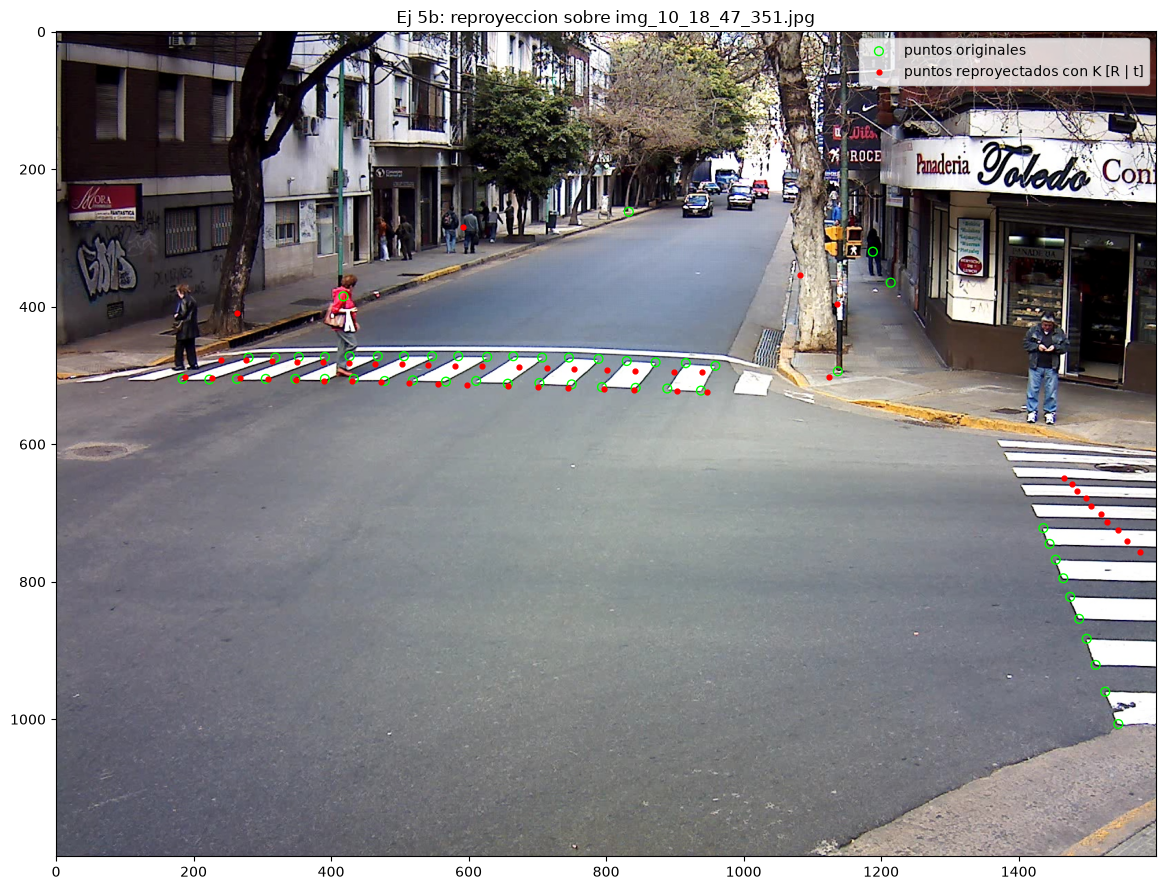

In [35]:
# Ejercicio 5b - Pose de la cámara a partir de gs_10_09_point_correspondences_v5.txt
# y reproyección de los puntos sobre img_10_18_47_351.jpg
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
print('----- EJERCICIO 5b -----')
np.set_printoptions(precision=3, suppress=True)

ptsVistaCero = np.loadtxt("salguero/gs_10_09_point_correspondences_v5.txt")
cantPts = ptsVistaCero.shape[1]
ptsMundoGs = alc.transpuesta(ptsVistaCero[1:4, :])   
ptsImgGs = alc.transpuesta(ptsVistaCero[4:6, :])

Q = alc.obtenerQ2d(ptsImgGs, ptsMundoGs)
H0 = alc.resolverDLT2D(Q)

R0, t0 = alc.obtenerPose2D(H0, K)
print('matriz de rotacion R para _351.jpg:')
print(R0)
print('vector de traslacion t para _351.jpg:')
print(t0)

Rt0 = np.zeros((3, 4))
Rt0[:, 0:3] = R0
Rt0[:, 3] = t0
P0 = alc.multiplicacion_matrices(K, Rt0)
print('matriz de proyeccion P = K [R | t]:')
print(P0)

reproyeccion = np.zeros((cantPts, 2))
errorReproy = np.zeros(cantPts)
for i in range(cantPts):
    puntoHomog = np.array([ptsMundoGs[i, 0], ptsMundoGs[i, 1], ptsMundoGs[i, 2], 1.0])
    proy = alc.matvec(P0, puntoHomog)
    reproyeccion[i] = proy[:2] / proy[2]
    errorReproy[i] = alc.norma(reproyeccion[i] - ptsImgGs[i], 2)
print('error de reproyeccion: medio = %.1f px, maximo = %.1f px' % (np.mean(errorReproy), np.max(errorReproy)))

img351 = mpimg.imread("salguero/img_10_18_47_351.jpg")
plt.figure(figsize=(12, 9))
plt.imshow(img351)
plt.scatter(ptsImgGs[:, 0], ptsImgGs[:, 1], s=40, facecolors='none', edgecolors='lime', label='puntos originales')
plt.scatter(reproyeccion[:, 0], reproyeccion[:, 1], s=12, color='red', label='puntos reproyectados con K [R | t]')
plt.legend()
plt.title('Ej 5b: reproyeccion sobre img_10_18_47_351.jpg')
plt.tight_layout()
plt.show()

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

#### Ejercicio 5c, Celda 1
Tenemos tomas desde una cámara fija, por lo cual infiero que las consideramos bajo la misma homografía $H$, usando
como $Z=0$ el plano de la calle y la imagen:

$$\lambda \begin{pmatrix} u \\ v \\ 1 \end{pmatrix} = H \begin{pmatrix} X \\ Y \\ 1 \end{pmatrix}$$

Estimamos $H$ por DLT con los 51 puntos de referencia del 5b (todos sobre la calle) y la validamos reproyectando esos puntos sobre la imagen.

In [36]:
# 5c
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import alc

np.set_printoptions(precision=2, suppress=True)


ptsGs = np.loadtxt("salguero/gs_10_09_point_correspondences_v5.txt")
ptsMundoGs = alc.transpuesta(ptsGs[1:3, :])
ptsImgGs = alc.transpuesta(ptsGs[4:6, :])

# cámara del 5b: P0 = K [R | t]. Los agentes están en Z = 0, así que H = K [r1 r2 t]
H = np.hstack([P0[:, 0:2], P0[:, 3:4]])
H_inv = alc.matriz_inversa(H)

# coordenadas homogéneas a "reales"
deshomogeneizar = lambda p: p[:2] / p[2]

# proyecta un punto de la calle a la foto
calleAImagen = lambda H, X, Y: deshomogeneizar(alc.matvec(H, np.array([X, Y, 1.0])))

# toma un pixel marcado y lo transforma en metros
imagenACalle = lambda H_inv, u, v: deshomogeneizar(alc.matvec(H_inv, np.array([u, v, 1.0])))

# estimación de la velocidad
velocidadesPorCuadro = lambda P, t: (
    np.array([alc.norma(d, 2) for d in np.diff(P, axis=0)]) / np.diff(t),
    (t[:-1] + t[1:]) / 2,
)

errores = np.array([alc.norma(calleAImagen(H, ptsMundoGs[i, 0], ptsMundoGs[i, 1]) - ptsImgGs[i], 2)
                    for i in range(len(ptsMundoGs))])
print("H =")
print(H)
print("error de reproyeccion: medio = %.1f px, maximo = %.1f px" % (np.mean(errores), np.max(errores)))

H =
[[ 2700.04   834.19 17270.57]
 [  -35.22   177.45 17182.59]
 [   -0.23     0.97    33.62]]
error de reproyeccion: medio = 57.8 px, maximo = 252.4 px


#### Ejercicio 5c, celda 2

Para cada "agente" marcamos a mano su posición en 16 de las 46 capturas (un tercio), con un script auxiliar (`marcar_salguero.py`) que guarda los píxeles en `salguero/marcados.csv`.

Cada píxel se lleva a la calle con $H^{-1}$, y con esas posiciones calculamos:
- la **velocidad cuadro a cuadro**: $v_k = \|P_{k+1} - P_k\| / (t_{k+1} - t_k)$, con el $\Delta t$ real de cada par;
- la **velocidad media**: desplazamiento total sobre tiempo total;
- la **velocidad por cuadrados mínimos**: ajustamos rectas $X(t)$ e $Y(t)$, y la norma de sus pendientes es la velocidad.

La velocidad cuadro a cuadro es ruidosa: como la cámara mira de forma muy rasante, unos pocos píxeles de error al marcar son decenas de centímetros en la calle. Por eso informamos el valor por cuadrados mínimos, que usa todas las capturas a la vez.

In [37]:
marcados = pd.read_csv("salguero/marcados.csv")
agentesCol = np.array(marcados["agente"])
tCol = np.array(marcados["t"], dtype=float)
uCol = np.array(marcados["u"], dtype=float)
vCol = np.array(marcados["v"], dtype=float)

agentes = ["taxi", "camioneta", "senora"]
colores = {"taxi": "gold", "camioneta": "deepskyblue", "senora": "red"}
resultados = {}

for agente in agentes:
    filas = agentesCol == agente
    t = tCol[filas]
    t = t - t[0]                                    # segundos desde la primera captura
    uv = alc.transpuesta(np.array([uCol[filas], vCol[filas]]))

    # de la imagen a la calle con H^-1 (H = K [r1 r2 t] del 5b)
    P = np.zeros((len(t), 2))
    for k in range(len(t)):
        P[k] = imagenACalle(H_inv, uv[k, 0], uv[k, 1])

    # velocidad frame a frame, con el Δt real de cada par de capturas
    v, tm = velocidadesPorCuadro(P, t)

    # velocidad media: desplazamiento total / tiempo total
    vMedia = alc.norma(P[-1] - P[0], 2) / (t[-1] - t[0])

    resultados[agente] = {"t": t, "uv": uv, "P": P, "v": v, "tm": tm, "vMedia": vMedia}

    print(agente + ":")
    print("  posicion inicial (X, Y) = " + str(P[0]) + " m, final = " + str(P[-1]) + " m")
    print("  velocidad frame a frame (km/h): " + str(v * 3.6))
    print("  velocidad media (desplazamiento / tiempo): %.2f m/s = %.1f km/h" % (vMedia, vMedia * 3.6))

taxi:
  posicion inicial (X, Y) = [ 6.37 96.01] m, final = [-2.24 -5.13] m
  velocidad frame a frame (km/h): [61.94 70.25 58.61 53.56 59.69 98.96 97.93 70.65 89.88 68.86 68.51 71.47
 70.47 71.8  59.99]
  velocidad media (desplazamiento / tiempo): 19.54 m/s = 70.3 km/h
camioneta:
  posicion inicial (X, Y) = [  9.93 115.29] m, final = [2.16 8.96] m
  velocidad frame a frame (km/h): [ 79.06  46.7   66.18  56.17  57.14 113.03  88.9   91.58  69.    76.76
  72.82  89.    78.31  78.53  66.9 ]
  velocidad media (desplazamiento / tiempo): 20.52 m/s = 73.9 km/h
senora:
  posicion inicial (X, Y) = [-1.28  0.8 ] m, final = [5.61 4.12] m
  velocidad frame a frame (km/h): [8.33 9.01 1.07 7.62 6.43 5.57 5.07 6.79 6.47 2.74 4.76 3.89 8.25 3.86
 2.52]
  velocidad media (desplazamiento / tiempo): 1.47 m/s = 5.3 km/h


#### Ejercicio 5c, celda 3

A la izquierda, los puntos marcados a mano sobre la última captura (en píxeles, con el eje $v$ creciendo hacia abajo) y, en punteado, la recta ajustada en la calle proyectada de nuevo a la imagen con $H$.

A la derecha, la vista de planta: las mismas posiciones en metros junto a los puntos de referencia del 5b. Los autos avanzan por Salguero (eje $Y$) y la señora cruza por la senda peatonal (eje $X$).

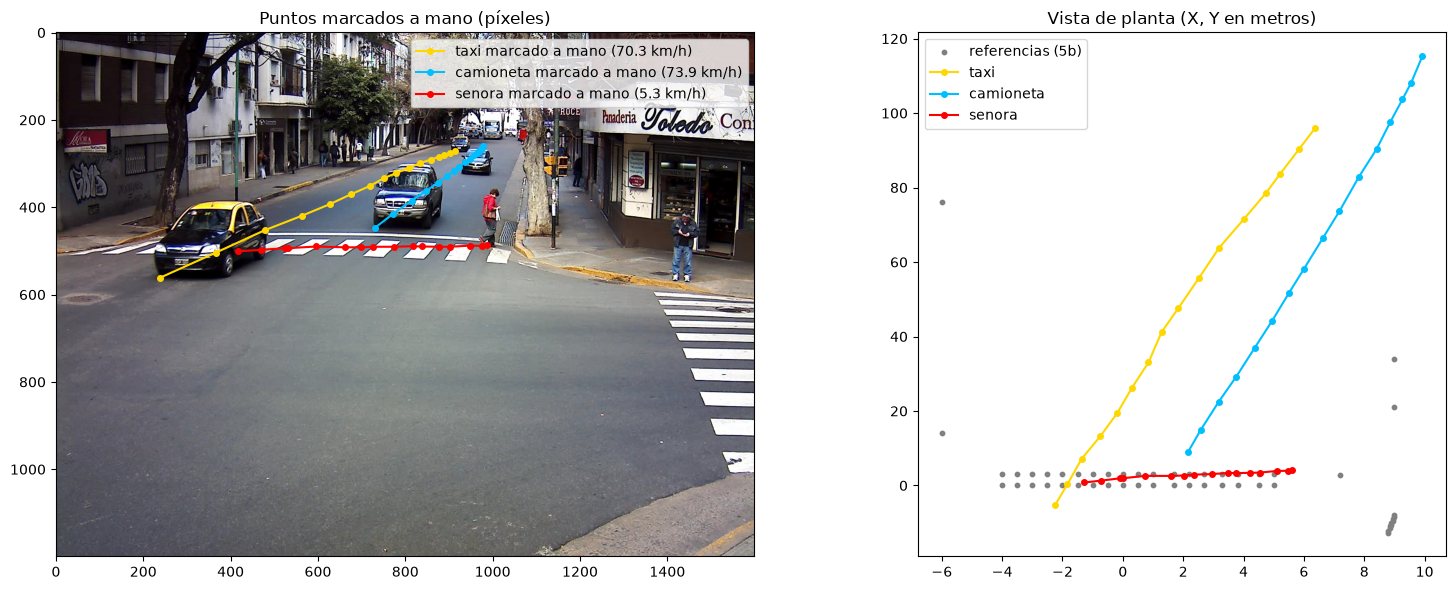

In [38]:
imgFinal = mpimg.imread("salguero/gs_dataset/img_10_18_52_546.jpg")

fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1]})

# izquierda: puntos marcados a mano (píxeles) sobre la última captura
axs[0].imshow(imgFinal)
for agente in agentes:
    r = resultados[agente]
    axs[0].plot(r["uv"][:, 0], r["uv"][:, 1], "o-", color=colores[agente], ms=4,
                label=agente + " marcado a mano (%.1f km/h)" % (r["vMedia"] * 3.6))
axs[0].legend()
axs[0].set_title("Puntos marcados a mano (píxeles)")

# derecha: posiciones en la calle (metros) junto a los puntos de referencia
axs[1].scatter(ptsMundoGs[:, 0], ptsMundoGs[:, 1], s=10, color="gray", label="referencias (5b)")
for agente in agentes:
    P = resultados[agente]["P"]
    axs[1].plot(P[:, 0], P[:, 1], "o-", color=colores[agente], ms=4, label=agente)
axs[1].legend()
axs[1].set_title("Vista de planta (X, Y en metros)")

plt.tight_layout()
plt.show()

#### Ejercicio 5c, celda 4
Para cada "agente" graficamos la velocidad cuadro a cuadro y, en línea punteada, la obtenida por cuadrados mínimos. Las oscilaciones cuadro a cuadro se explican por el error de marcado. El pico que tienen ambos autos cerca de $t \approx 2$ s, en el mismo intervalo, sugiere además un error en el tiempo registrado de esa captura.

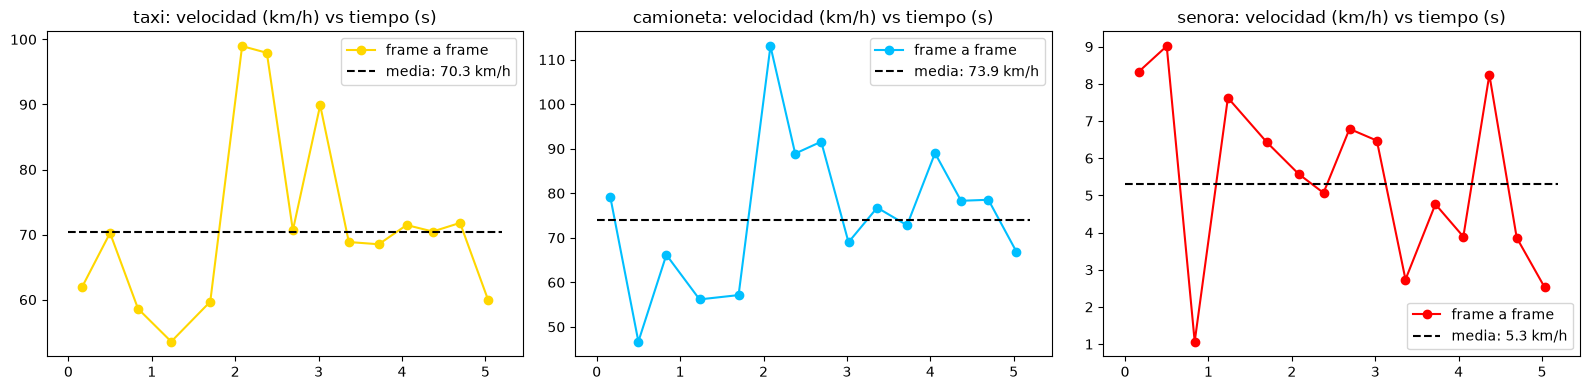

In [39]:
# Ejercicio 5c - Velocidad en función del tiempo
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for i, agente in enumerate(agentes):
    r = resultados[agente]
    axs[i].plot(r["tm"], r["v"] * 3.6, "o-", color=colores[agente], label="frame a frame")
    axs[i].plot([r["t"][0], r["t"][-1]], [r["vMedia"] * 3.6] * 2, "k--",
                label="media: %.1f km/h" % (r["vMedia"] * 3.6))
    axs[i].set_title(agente + ": velocidad (km/h) vs tiempo (s)")
    axs[i].legend()
plt.tight_layout()
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

### Solución

#### Ejercicio 6.a — Estimación de la pose mediante POSIT

Para estimar la pose de la cámara a partir de la imagen `row_00248.png`, utilizamos el algoritmo **POSIT para puntos coplanares** presentado en el enunciado. Tenemos en cuenta cinco correspondencias entre posiciones conocidas del mundo y sus coordenadas en la imagen: el centro de la H y sus cuatro extremos. El punto blanco permite identificar cuál es la esquina superior izquierda en el sistema de referencia de la H.

Los puntos tridimensionales se encuentran en el plano $W=0$ y se expresan en metros. La matriz intrínseca $K$ se obtiene de `heli/K.csv`. Como las distancias focales $f_x$ y $f_y$ son diferentes, la implementación reescala la coordenada vertical para trabajar con una focal común.

En cada iteración, POSIT resuelve los sistemas lineales del método POS, construye dos poses candidatas a partir de $I_0\pm\lambda n$ y $J_0\pm\mu n$, y selecciona la pose que proyecta todos los puntos delante de la cámara y presenta menor error RMS. Las iteraciones se detienen cuando la mejora del RMS es menor que la tolerancia indicada.

Verificamos la pose recuperada mediante la ortogonalidad de $R$ y el error de reproyección de los puntos observados.

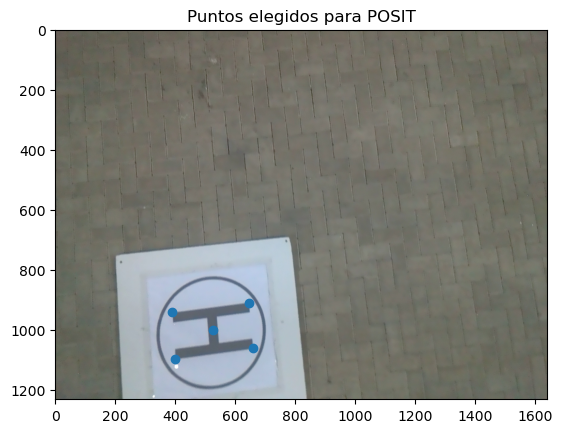

Rotación actual R:
[[-0.12 -0.96  0.27]
 [-0.98  0.07 -0.18]
 [ 0.16 -0.29 -0.95]]

Traslación actual t (m):
[-0.69  0.89  4.41]

Puntos válidos: 5 de 5
Error RMS (píxeles): 1.6437558546382887

R^T R:
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]


In [49]:
# Ejercicio 6.a - Aplicación de POSIT a los puntos de la H
import dron as dron
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ruta_heli = "heli"

# Datos tridimensionales: columnas U, V, W de object_points.csv (en metros)
objPts_dron = np.loadtxt(
    os.path.join(ruta_heli, "object_points.csv"),
    delimiter=";", skiprows=1, usecols=(1, 2, 3)
)

# Coordenadas observadas en row_00248.png, en el mismo orden que objPts_dron
imgPts_dron = np.array([
    [524, 1002],  # centro de la H
    [400, 1097],  # superior izquierda: punto blanco
    [389,  941],  # superior derecha
    [644,  911],  # inferior derecha
    [660, 1062]   # inferior izquierda
], dtype=float)

K_dron = np.loadtxt(os.path.join(ruta_heli, "K.csv"), delimiter=";")

# Visualización de las correspondencias elegidas
imagen_dron = mpimg.imread(os.path.join(ruta_heli, "row_00248.png"))
plt.figure()
plt.imshow(imagen_dron)
plt.scatter(imgPts_dron[:, 0], imgPts_dron[:, 1])
plt.title("Puntos elegidos para POSIT")
plt.show()

# Estimamos la pose actual
pose_dron = dron.aplicarPOSIT(objPts_dron, imgPts_dron, K_dron, MaxIt=50, atol=1e-4)
if pose_dron is None:
    raise ValueError("POSIT no encontró una pose válida para las correspondencias dadas")
R_dron, t_dron = pose_dron

validas_dron, rms_dron = dron.evaluarPose(
    R_dron, t_dron, objPts_dron, imgPts_dron, K_dron
)

print("Rotación actual R:")
print(R_dron)
print("\nTraslación actual t (m):")
print(t_dron)
print("\nPuntos válidos:", validas_dron, "de", len(objPts_dron))
print("Error RMS (píxeles):", rms_dron)
print("\nR^T R:")
print(alc.multiplicacion_matrices(alc.transpuesta(R_dron), R_dron))


#### Ejercicio 6.b — Pose deseada para ubicarse sobre la H

Buscamos una pose en la que la cámara quede exactamente encima del centro de la H y su eje óptico sea perpendicular al plano de aterrizaje. Conservamos la altura estimada en el inciso anterior y elegimos la orientación de modo que el punto blanco se proyecte **arriba a la izquierda** de la imagen.

Del modelo de cámara utilizado en la ecuación (15) del enunciado,

$$
P_c=RP_w+t,
$$

obtenemos la posición $C$ del centro de cámara en coordenadas del mundo al imponer $P_c=0$:

$$
C=-R^Tt.
$$

Como la H se encuentra en $W=0$, la altura de la cámara corresponde a la tercera componente $C_3$, **no necesariamente a $t_3$**. La posición y orientación deseadas son

$$
C_{\mathrm{des}}=(0,0,C_3)^T, \qquad
R_{\mathrm{des}}=\begin{pmatrix}1&0&0\\0&-1&0\\0&0&-1\end{pmatrix}.
$$

La traslación de la nueva pose se calcula mediante $t_{\mathrm{des}}=-R_{\mathrm{des}}C_{\mathrm{des}}$. También calculamos la rotación relativa $R_{\mathrm{des}}R^T$ y el desplazamiento del centro de cámara entre ambas posiciones.

Finalmente, reproyectamos los puntos con la pose deseada para comprobar que el centro de la H coincida con el punto principal $(c_u,c_v)$ y que la esquina marcada aparezca arriba a la izquierda. Estos resultados describen la **pose de la cámara**; para convertirlos en comandos de vuelo sería necesario conocer la posición y orientación de la cámara respecto del cuerpo del dron.

---

In [50]:
# Ejercicio 6.b - Estimación de la pose deseada

# Centro de la cámara actual en coordenadas del mundo
C_dron = -alc.matvec(alc.transpuesta(R_dron), t_dron)
altura_dron = C_dron[2]

# Cámara vertical orientada hacia el plano W = 0
R_des = np.array([
    [1.,  0.,  0.],
    [0., -1.,  0.],
    [0.,  0., -1.]
])

# Centro deseado: justo sobre el centro de la H, a la misma altura
C_des = np.array([0., 0., altura_dron])
t_des = -alc.matvec(R_des, C_des)

# Cambio de orientación y desplazamiento expresado en ejes actuales de cámara
R_corregida = alc.multiplicacion_matrices(R_des, alc.transpuesta(R_dron))
dC = C_des - C_dron
d_cam = alc.matvec(R_dron, dC)

# Comprobación mediante reproyección de los puntos del plano
imgPts_deseados = dron.reproyectar_puntos(R_des, t_des, objPts_dron, K_dron)

print("Centro de cámara actual C (m):", C_dron)
print("Altura conservada (m):", altura_dron)
print("Centro de cámara deseado C_des (m):", C_des)
print("\nRotación deseada R_des:")
print(R_des)
print("\nTraslación deseada t_des (m):", t_des)
print("\nRotación relativa R_corregida:")
print(R_corregida)
print("\nDesplazamiento en ejes actuales de cámara (m):", d_cam)
print("\nProyección del centro de la H:", imgPts_deseados[0])
print("Punto principal de K:", K_dron[0, 2], K_dron[1, 2])
print("Proyección de la esquina marcada:", imgPts_deseados[1])


Centro de cámara actual C (m): [0.11 0.54 4.52]
Altura conservada (m): 4.5230968441864565
Centro de cámara deseado C_des (m): [0.   0.   4.52]

Rotación deseada R_des:
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]]

Traslación deseada t_des (m): [-0.   -0.    4.52]

Rotación relativa R_corregida:
[[-0.12 -0.98  0.16]
 [ 0.96 -0.07  0.29]
 [-0.27  0.18  0.95]]

Desplazamiento en ejes actuales de cámara (m): [0.53 0.07 0.14]

Proyección del centro de la H: [819.5 615.5]
Punto principal de K: 819.5 615.5
Proyección de la esquina marcada: [746.2631201782102 488.8500476037153]
